In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

import torch
from transformers import (
    DistilBertTokenizer,
    DistilBertForSequenceClassification
)
from torch.utils.data import Dataset, DataLoader

# =====================================================
# Dataset Path
# =====================================================

DATASET_PATH = Path(
    "/projects/Datasets/phishing/phishingemails/Phishing_Email.csv"
)

# Check if dataset exists
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATASET_PATH}\n"
        "Please download the Kaggle dataset first."
    )

# =====================================================
# Load Dataset
# =====================================================

df = pd.read_csv(DATASET_PATH)

# =====================================================
# Basic Exploration
# =====================================================

print("=" * 60)
print("First 5 Rows")
print("=" * 60)
print(df.head())

print("\n" + "=" * 60)
print("Dataset Shape")
print("=" * 60)
print(df.shape)

print("\n" + "=" * 60)
print("Email Type Distribution")
print("=" * 60)
print(df["Email Type"].value_counts())

First 5 Rows
   Unnamed: 0                                         Email Text  \
0           0  re : 6 . 1100 , disc : uniformitarianism , re ...   
1           1  the other side of * galicismos * * galicismo *...   
2           2  re : equistar deal tickets are you still avail...   
3           3  \nHello I am your hot lil horny toy.\n    I am...   
4           4  software at incredibly low prices ( 86 % lower...   

       Email Type  
0      Safe Email  
1      Safe Email  
2      Safe Email  
3  Phishing Email  
4  Phishing Email  

Dataset Shape
(18650, 3)

Email Type Distribution
Email Type
Safe Email        11322
Phishing Email     7328
Name: count, dtype: int64


In [3]:
# Check for nulls and duplicates
print("Nulls:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

# Drop the unnamed index column, drop nulls and duplicates
df = df.drop(columns=['Unnamed: 0'])
df = df.dropna()
df = df.drop_duplicates()

print("\nShape after cleaning:", df.shape)
print(df['Email Type'].value_counts())

Nulls:
 Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64

Duplicates: 0

Shape after cleaning: (17538, 2)
Email Type
Safe Email        10980
Phishing Email     6558
Name: count, dtype: int64


In [4]:
df['label'] = df['Email Type'].apply(lambda x: 1 if x == 'Phishing Email' else 0)
print(df[['Email Type', 'label']].head())

       Email Type  label
0      Safe Email      0
1      Safe Email      0
2      Safe Email      0
3  Phishing Email      1
4  Phishing Email      1


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df['Email Text'].tolist(),
    df['label'].tolist(),
    test_size=0.2,
    random_state=42,
    stratify=df['label']
)

print(f"Train size: {len(X_train)}")
print(f"Test size: {len(X_test)}")

Train size: 14030
Test size: 3508


In [6]:
from transformers import DistilBertTokenizer

tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

# Quick test on one email
sample = X_train[0]
tokens = tokenizer(sample, truncation=True, padding='max_length', max_length=256)
print("Sample email (first 200 chars):", sample[:200])
print("\nToken IDs (first 20):", tokens['input_ids'][:20])
print("Token count:", len(tokens['input_ids']))

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Sample email (first 200 chars): storage model security stinson , i have added a time bomb and security file check to the model . we are ready to release it to brad , and improve the model from his feed back . zimin

Token IDs (first 20): [101, 5527, 2944, 3036, 2358, 7076, 2239, 1010, 1045, 2031, 2794, 1037, 2051, 5968, 1998, 3036, 5371, 4638, 2000, 1996]
Token count: 256


In [7]:
import torch
from torch.utils.data import Dataset

class PhishingDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_length=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            truncation=True,
            padding='max_length',
            max_length=self.max_length,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_dataset = PhishingDataset(X_train, y_train, tokenizer)
test_dataset = PhishingDataset(X_test, y_test, tokenizer)

print("Train dataset size:", len(train_dataset))
sample_item = train_dataset[0]
print("Sample input_ids shape:", sample_item['input_ids'].shape)
print("Sample label:", sample_item['label'])

Train dataset size: 14030
Sample input_ids shape: torch.Size([256])
Sample label: tensor(0)


In [11]:
import os
os.makedirs('data', exist_ok=True)

In [12]:
import pickle

with open('data/train_dataset.pkl', 'wb') as f:
    pickle.dump({'texts': X_train, 'labels': y_train}, f)

with open('data/test_dataset.pkl', 'wb') as f:
    pickle.dump({'texts': X_test, 'labels': y_test}, f)

print("Datasets saved")

Datasets saved


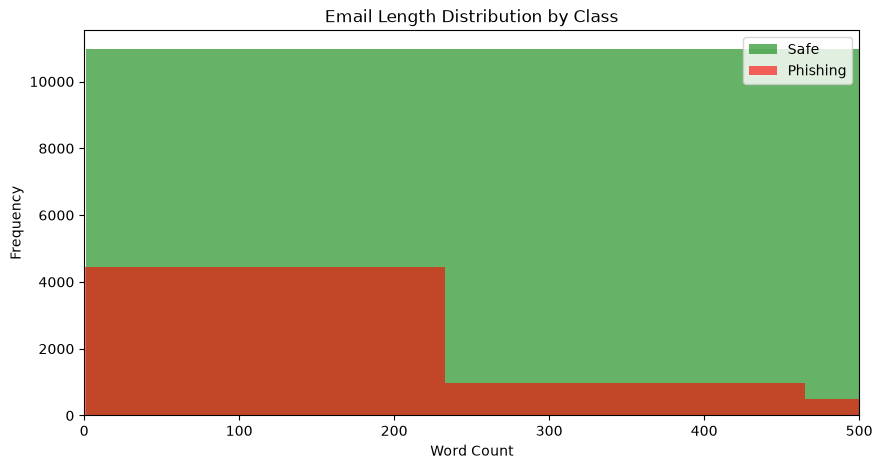

Average phishing email length: 318.31091796279355
Average safe email length: 698.4000910746812


In [13]:
import matplotlib.pyplot as plt

# Email length distribution
df['text_length'] = df['Email Text'].apply(lambda x: len(x.split()))

plt.figure(figsize=(10, 5))
plt.hist(df[df['label']==0]['text_length'], bins=50, alpha=0.6, label='Safe', color='green')
plt.hist(df[df['label']==1]['text_length'], bins=50, alpha=0.6, label='Phishing', color='red')
plt.xlim(0, 500)
plt.xlabel('Word Count')
plt.ylabel('Frequency')
plt.title('Email Length Distribution by Class')
plt.legend()
plt.show()

print("Average phishing email length:", df[df['label']==1]['text_length'].mean())
print("Average safe email length:", df[df['label']==0]['text_length'].mean())